In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
import sklearn

In [34]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [35]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.


In [36]:
import pandas as pd
print(pd.__version__)

2.2.2


In [37]:
df = pd.read_csv('IMDB Dataset.csv')
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. The filming tec...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [38]:
df.shape

(500, 2)

In [39]:
df.columns

Index(['review', 'sentiment'], dtype='object')

In [40]:
df["sentiment"].value_counts()

sentiment
negative    263
positive    237
Name: count, dtype: int64

In [41]:
def remove_stopwords(review):
    return " ".join(word for word in review.split() if word.lower() not in stopwords.words('english'))

In [42]:
%pip install scikit-learn nltk

Note: you may need to restart the kernel to use updated packages.


In [43]:
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import nltk

from nltk.corpus import stopwords

print("All libraries imported successfully")

All libraries imported successfully


In [44]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Microsoft\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [45]:
%pip install wordcloud

Note: you may need to restart the kernel to use updated packages.


In [46]:
from wordcloud import WordCloud

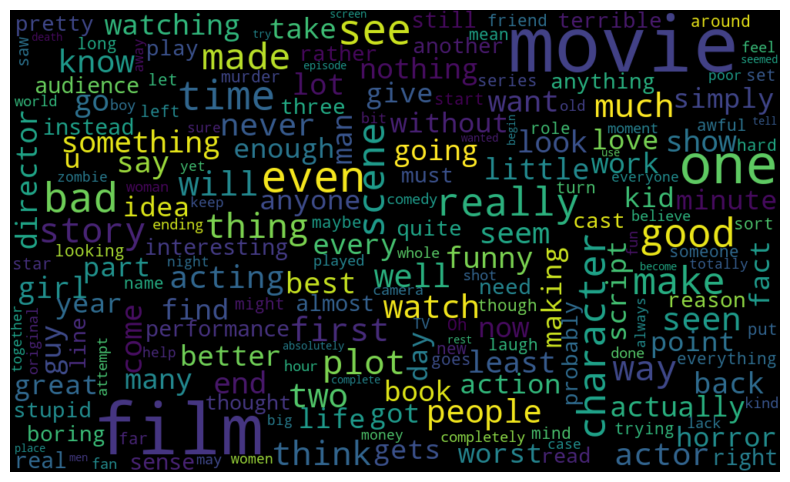

In [47]:
neg_revs = " ".join(
    df['review'][df['sentiment'] == 'negative'].astype(str)
)

wc = WordCloud(
    height=600,
    width=1000,
    max_font_size=100
).generate(neg_revs)

plt.figure(figsize=(12, 6))
plt.imshow(wc, interpolation='bilinear')
plt.axis("off")
plt.show()

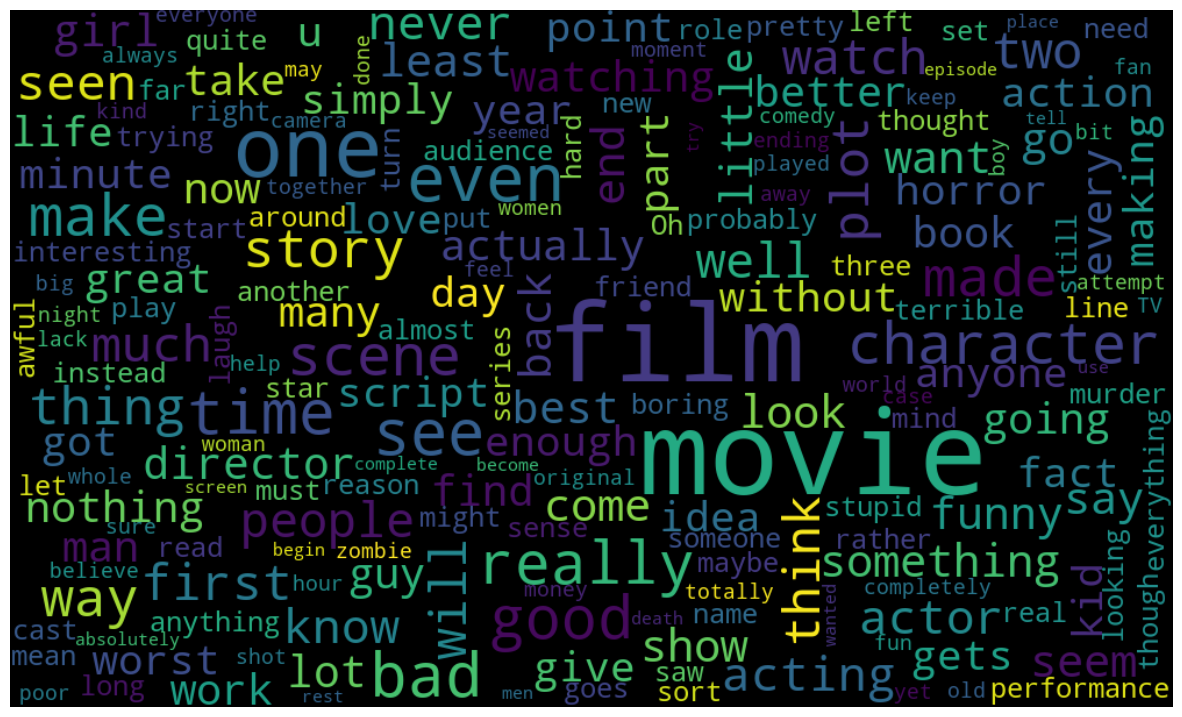

In [48]:
plt.figure(figsize=(15,12))
plt.imshow(wc.generate(neg_revs), interpolation='bilinear')
plt.axis('off')
plt.show()

In [49]:
from sklearn.feature_extraction.text import TfidfVectorizer

cv = TfidfVectorizer(max_features=2500)

reviews = cv.fit_transform(df['review']).toarray()

In [50]:
from sklearn.feature_extraction.text import TfidfVectorizer

cv = TfidfVectorizer(max_features=2500)

reviews = cv.fit_transform(df['review']).toarray()

print(reviews.shape)

(500, 2500)


In [51]:
df = pd.read_csv("IMDB Dataset.csv")

In [52]:
df['sentiment'] = df['sentiment'].map({
    'positive': 1,
    'negative': 0
}).astype(int)

In [53]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    reviews,
    df['sentiment'],
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (400, 2500)
Testing data: (100, 2500)


In [54]:
from sklearn.linear_model import LogisticRegression

In [55]:
model = LogisticRegression()

In [56]:
from sklearn.model_selection import train_test_split

review_train, review_test, sent_train, sent_test = train_test_split(
    reviews,
    df['sentiment'],
    test_size=0.15,
    random_state=42
)

print(review_train.shape)
print(review_test.shape)

(425, 2500)
(75, 2500)


In [57]:
model.fit(review_train, sent_train)

LogisticRegression()

In [58]:
predict = model.predict(X_test)

In [61]:
from sklearn.metrics import confusion_matrix, accuracy_score
predict = model.predict(X_test)
cm = confusion_matrix(y_test, predict, labels=model.classes_)


In [69]:
from sklearn.metrics import ConfusionMatrixDisplay

In [71]:
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)

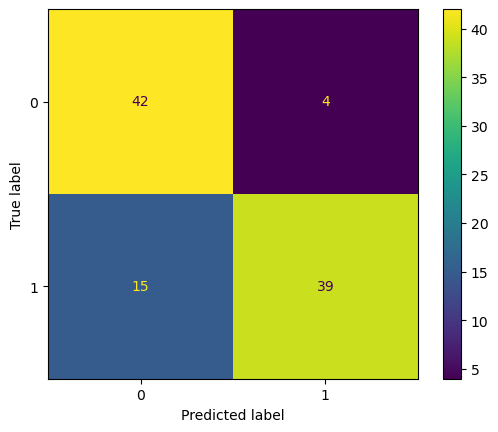

In [72]:
display.plot()
plt.show()

In [65]:
from sklearn.metrics import accuracy_score
predict = model.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, predict) * 100, 2), "%")

Accuracy: 81.0 %


In [66]:
import pickle as pk
pk.dump(model, open('model.pkl', 'wb'))

In [67]:
pk.dump(cv,open('scalar.pkl','wb'))